# **MUHAMMAD TAYYAB IFTIKHAR

## **APPLYING EFFICIENTNET FOR FACIAL CLUSTRING DATA**

### **DATASET OVERVIEW**

The given appears to be a large-scale facial recognition dataset designed for training deep learning models for facial classification. Here's a breakdown of the key components:

**Training Set:**

*Size:* Over 140,000 images.

*Content:* 7,000 unique identities, with each identity having 20 images. These images are stored in separate folders, with each folder corresponding to a unique identity.

This Dataset will be used for training and as well as for validaion of my model.

**Test Set:**

*Size:* 35,000 images, with 5 images per identity. These images are randomly assigned a number between 1 and 35,000 for identification purposes.

*Content:* The test set contains no labels, so the model is required to predict the identities based on the facial features from the images.

This dataset will use for prediction after the training the model will predict labels on this dataset.

**INSTALLING EFFICIENTNET FROM PYTORCH**

In [ ]:
!pip install efficientnet-pytorch


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 112.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 90.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 84.4 MB/s eta 0:00:00
  Created wheel for efficientnet-pytorch: filename=efficientnet_pytorch-0.7.1-py3-none-any.whl size=16426 sha256=8d9606cfac602525233838d42299877f1124e97b578e096b

**IMPORTING NECESSORY LIBRARIES AND PACKAGES**

In [ ]:
import os
import cv2
import random
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.model_selection import train_test_split
import torch.nn as nn
from efficientnet_pytorch import EfficientNet
from tqdm import tqdm
import pandas as pd
from tqdm import tqdm
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

### **LOADING THE DATASET AND UNZIPPING IT**

I used the Kaggle API to download the dataset by uploading your kaggle.json key, authenticating, and then downloading and unzipping the dataset into a dataset folder

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"tayyabiftikhar","key":"6bbb086b7374e272b281d21866b36200"}'}

In [ ]:
!mkdir -p /root/.config/kaggle
!mv kaggle.json /root/.config/kaggle/
!chmod 600 /root/.config/kaggle/kaggle.json


In [ ]:
!kaggle competitions download -c face-classification-deep-learning-cs-405


In [ ]:
!unzip face-classification-deep-learning-cs-405.zip -d dataset


Streaming output truncated to the last 5000 lines.
  inflating: dataset/dataset/train/n008922/0001_01.jpg  
  inflating: dataset/dataset/train/n008922/0007_02.jpg  
  inflating: dataset/dataset/train/n008922/0011_01.jpg  
  inflating: dataset/dataset/train/n008922/0015_01.jpg  
  inflating: dataset/dataset/train/n008922/0019_01.jpg  
  inflating: dataset/dataset/train/n008922/0025_01.jpg  
  inflating: dataset/dataset/train/n008922/0037_01.jpg  
  inflating: dataset/dataset/train/n008922/0044_01.jpg  
  inflating: dataset/dataset/train/n008922/0070_01.jpg  
  inflating: dataset/dataset/train/n008922/0093_01.jpg  
  inflating: dataset/dataset/train/n008922/0123_02.jpg  
  inflating: dataset/dataset/train/n008922/0129_01.jpg  
  inflating: dataset/dataset/train/n008922/0146_01.jpg  
  inflating: dataset/dataset/train/n008922/0154_01.jpg  
  inflating: dataset/dataset/train/n008922/0183_01.jpg  
  inflating: dataset/dataset/train/n008922/0185_01.jpg  
  inflating: dataset/dataset/train/n0

### **PREPARE TRANSFORM AND LOAD THE DATASET**

I have split the data in an 80:10:10 ratio for training, testing, and validation, respectively, ensuring that from each class

Dataloaders are used to load the data in small batches because storing the entire dataset at once would take up too much memory. Loading data in chunks makes it easier to work with large datasets that can't fit in memory all at once. It also ensures that the dataset is shuffled before reloading for every epoch.



In [ ]:
# CUSTOM DATASET CLASS
class FaceDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        if self.transform:
            image = self.transform(image=image)['image']
        return image, label

dataset_root = '/content/dataset/dataset/train'
class_names = sorted(os.listdir(dataset_root))
class_to_idx = {cls_name: i for i, cls_name in enumerate(class_names)}

# LOAD IMAGE PATHS
all_samples = []
for cls_name in class_names:
    cls_folder = os.path.join(dataset_root, cls_name)
    for img_name in os.listdir(cls_folder):
        img_path = os.path.join(cls_folder, img_name)
        label = class_to_idx[cls_name]
        all_samples.append((img_path, label))

random.shuffle(all_samples)

# SPLIT THE DATA
train_data, temp_data = train_test_split(all_samples, test_size=0.2, random_state=42)
val_data, test_data = train_test_split(temp_data, test_size=0.5, random_state=42)

# DEFINE TRANSFORMATIONS
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=15, p=0.3),
    A.RandomBrightnessContrast(p=0.2),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

test_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# CREATE DATA LOADERS
train_dataset = FaceDataset(train_data, transform=train_transform)
val_dataset   = FaceDataset(val_data, transform=test_transform)
test_dataset  = FaceDataset(test_data, transform=test_transform)

BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# PRINT DATA INFO
print(f"Train size: {len(train_dataset)}")
print(f"Val size: {len(val_dataset)}")
print(f"Test size: {len(test_dataset)}")
print(f"Class mapping: {class_to_idx}")


Train size: 112000
Val size: 14000
Test size: 14000
Class mapping: {'n000001': 0, 'n000002': 1, 'n000003': 2, 'n000004': 3, 'n000005': 4, 'n000008': 5, 'n000011': 6, 'n000012': 7, 'n000013': 8, 'n000014': 9, 'n000015': 10, 'n000016': 11, 'n000017': 12, 'n000018': 13, 'n000019': 14, 'n000020': 15, 'n000021': 16, 'n000022': 17, 'n000023': 18, 'n000024': 19, 'n000025': 20, 'n000026': 21, 'n000027': 22, 'n000029': 23, 'n000030': 24, 'n000031': 25, 'n000034': 26, 'n000035': 27, 'n000036': 28, 'n000037': 29, 'n000038': 30, 'n000040': 31, 'n000041': 32, 'n000042': 33, 'n000043': 34, 'n000044': 35, 'n000045': 36, 'n000046': 37, 'n000047': 38, 'n000048': 39, 'n000049': 40, 'n000050': 41, 'n000051': 42, 'n000052': 43, 'n000053': 44, 'n000054': 45, 'n000055': 46, 'n000056': 47, 'n000057': 48, 'n000058': 49, 'n000059': 50, 'n000060': 51, 'n000061': 52, 'n000062': 53, 'n000063': 54, 'n000066': 55, 'n000067': 56, 'n000068': 57, 'n000069': 58, 'n000070': 59, 'n000071': 60, 'n000074': 61, 'n000075': 6

### **MODEL TRAINING AND EVALUATION**

In [ ]:
# DETERMINE DEVICE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# INITIALIZE MODEL
num_classes = len(class_to_idx)
model = EfficientNet.from_pretrained("efficientnet-b0", num_classes=num_classes)
model = model.to(device)

# DEFINE LOSS FUNCTION
criterion = nn.CrossEntropyLoss()

# SET OPTIMIZER
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

# CONFIGURE SCHEDULER
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2,
    threshold=0.0001, threshold_mode="abs", verbose=True
)

# ACCURACY CALCULATION
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, 1)
    return (preds == labels).float().mean()

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# TRAINING PROCESS
num_epochs = 10
for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_acc = 0

    # SHUFFLE TRAINING DATA
    train_loader.dataset.samples = random.sample(train_loader.dataset.samples, len(train_loader.dataset.samples))

    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{num_epochs}] Training")
    for images, labels in loop:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        acc = accuracy(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_acc += acc.item()

        loop.set_postfix(loss=loss.item(), acc=acc.item())

    # VALIDATION EVALUATION
    model.eval()
    val_loss = 0
    val_acc = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            acc = accuracy(outputs, labels)

            val_loss += loss.item()
            val_acc += acc.item()

    scheduler.step(val_loss)

    avg_train_loss = train_loss / len(train_loader)
    avg_train_acc = train_acc / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    avg_val_acc = val_acc / len(val_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_accuracies.append(avg_train_acc)
    val_accuracies.append(avg_val_acc)

    # EPOCH SUMMARY
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss/len(train_loader):.4f} | Train Acc: {train_acc/len(train_loader):.4f}")
    print(f"Val   Loss: {val_loss/len(val_loader):.4f} | Val   Acc: {val_acc/len(val_loader):.4f}")


Loaded pretrained weights for efficientnet-b0


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
Epoch [1/10] Training: 100%|██████████| 1750/1750 [12:04<00:00,  2.41it/s, acc=0.203, loss=4.57]



Epoch 1/10
Train Loss: 6.8122 | Train Acc: 0.0571
Val   Loss: 4.5692 | Val   Acc: 0.1926


Epoch [2/10] Training: 100%|██████████| 1750/1750 [12:03<00:00,  2.42it/s, acc=0.422, loss=2.61]



Epoch 2/10
Train Loss: 3.1906 | Train Acc: 0.3832
Val   Loss: 2.7415 | Val   Acc: 0.4763


...


Epoch 8/10
Train Loss: 0.3486 | Train Acc: 0.9137
Val   Loss: 2.0483 | Val   Acc: 0.6544


Epoch [9/10] Training: 100%|██████████| 1750/1750 [12:03<00:00,  2.42it/s, acc=0.891, loss=0.342]



Epoch 9/10
Train Loss: 0.3054 | Train Acc: 0.9229
Val   Loss: 2.0197 | Val   Acc: 0.6656


Epoch [10/10] Training: 100%|██████████| 1750/1750 [12:03<00:00,  2.42it/s, acc=1, loss=0.0811]



Epoch 10/10
Train Loss: 0.1022 | Train Acc: 0.9791
Val   Loss: 1.6598 | Val   Acc: 0.7370


The model shows strong learning, with training accuracy rising from 5.7% to 97.9% and validation accuracy improving to 73.7% by epoch 10. However, the growing gap between training and validation accuracy suggests slight overfitting. Performance is solid overall, but further gains might come from regularization or fine-tuning more base layers.

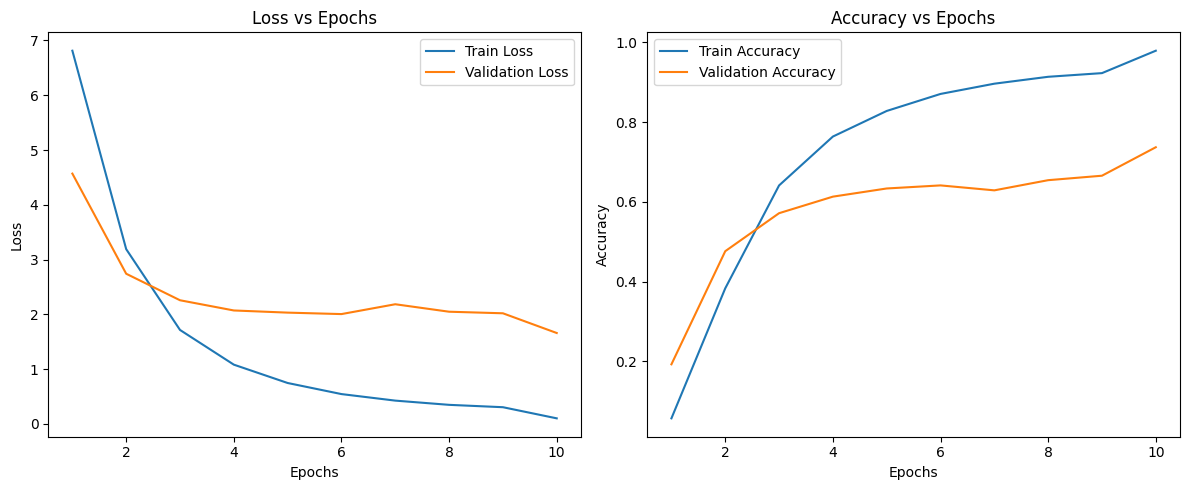

In [1]:

# PLOT
plt.figure(figsize=(12, 5))

# PLOT LOSS CURVE
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# PLOT ACCURACY CURVE
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label='Train Accuracy')
plt.plot(epochs, val_accuracies, label='Validation Accuracy')
plt.title('Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
# EVALUATE ON TEST SET
model.eval()
test_acc = 0
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Evaluating on Test Set"):
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        acc = accuracy(outputs, labels)

        test_acc += acc.item()

# CALCULATE AND PRINT TEST ACCURACY
test_acc = test_acc / len(test_loader)
print(f"\n✅ Test Accuracy: {test_acc:.4f}")


Evaluating on Test Set: 100%|██████████| 219/219 [00:41<00:00,  5.34it/s]


✅ Test Accuracy: 0.7354


### **HAVING PREDICTIONS ON ACTUAL TEST DATA**

In [ ]:
# LOAD THE TEST DATASET AND APPLY TRANSFORMATIONS
test_dir = '/content/dataset/dataset/test'
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
])

# CREATE A DATASET FOR TEST IMAGES
test_images = [f for f in os.listdir(test_dir) if f.endswith('.jpg')]
test_samples = [os.path.join(test_dir, img) for img in test_images]

# DEFINE CUSTOM TEST DATASET CLASS
class TestDataset(torch.utils.data.Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, img_path

# CREATE A DATA LOADER FOR THE TEST DATASET
test_dataset = TestDataset(test_samples, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# MAKE PREDICTIONS AND SAVE RESULTS
model.eval()
predictions = []
with torch.no_grad():
    for images, img_paths in tqdm(test_loader, desc="Predicting test set"):
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        predicted_labels = [list(class_to_idx.keys())[list(class_to_idx.values()).index(pred.item())] for pred in preds]
        for img_path, label in zip(img_paths, predicted_labels):
            img_name = os.path.basename(img_path)
            predictions.append((img_name, label))

# SAVE THE PREDICTIONS TO A CSV FILE
df = pd.DataFrame(predictions, columns=['image_name', 'label'])
df.to_csv('/content/sample_submission_1.csv', index=False)
print("Predictions saved to sample_submission_1.csv")


Predicting test set: 100%|██████████| 547/547 [02:27<00:00,  3.71it/s]

Predictions saved to sample_submission_1.csv
